| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../16_UNCERTAINTY_QUANTIFICATION/16_1_UNCERTAINTY_QUANTIFICATION.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_1_Performance.ipynb) |

# 17.1 ASIMILACIÓN DE DATOS

La asimilación combina un **modelo dinámico** y **observaciones parciales** para estimar el estado de un sistema a medida que llegan datos. Un sensor puede medir posición, mientras la velocidad queda oculta; el modelo conecta ambas. La pregunta no es solo ajustar una curva, sino actualizar de forma coherente lo que creemos sobre el estado y su incertidumbre.

Construiremos un filtro de Kalman para un objeto que se mueve en una dimensión. Después estudiaremos innovaciones, observaciones atípicas, un filtro de conjuntos y una actualización variacional. Los datos son sintéticos; conocemos la trayectoria verdadera para evaluar el método.

**Objetivos.** Derivar predicción y corrección, distinguir covarianzas de proceso y observación, interpretar diagnósticos y relacionar filtros con SciML. Requisitos: matrices, distribuciones gaussianas y ecuaciones dinámicas. Bibliotecas: NumPy, SciPy y Matplotlib.

## 1. Modelo de estado y de observación

Sea $x_n=(p_n,v_n)^T$, con posición y velocidad. El modelo discreto es
$$x_{n+1}=F x_n+w_n,\quad F=\begin{pmatrix}1&\Delta t\\0&1\end{pmatrix},\quad w_n\sim\mathcal N(0,Q).$$
Solo observamos posición:
$$y_n=H x_n+\varepsilon_n,\quad H=(1,0),\quad\varepsilon_n\sim\mathcal N(0,R).$$
Aquí $R$ es una matriz de tamaño $1\times1$; en el código guardaremos su único escalar. Supondremos ruido blanco, independiente entre pasos y entre proceso y observación. Son hipótesis que se deben revisar cuando el sensor tiene sesgo o memoria.

## 2. ¿Qué representa Q?

El modelo de velocidad constante no afirma que la velocidad real sea perfectamente constante. El ruido de proceso permite representar aceleraciones no resueltas. Para una aceleración idealizada como ruido blanco continuo de intensidad $q$,
$$Q=q\begin{pmatrix}\Delta t^3/3&\Delta t^2/2\\\Delta t^2/2&\Delta t\end{pmatrix}.$$
Se obtiene integrando la contribución de la aceleración a posición y velocidad durante un paso. No es la misma matriz que corresponde a una aceleración aleatoria constante en cada intervalo, que usa términos $\Delta t^4/4$, $\Delta t^3/2$ y $\Delta t^2$.

La elección afecta las unidades y la incertidumbre propagada. Un $Q$ demasiado pequeño hace al filtro rígido frente a cambios reales; un $R$ demasiado pequeño hace que persiga excesivamente el ruido del sensor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.optimize import minimize
rng = np.random.default_rng(171)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
dt, pasos, q, R = 0.2, 150, 0.08, 0.25**2
F = np.array([[1.0, dt], [0.0, 1.0]])
H = np.array([[1.0, 0.0]])
Q = q*np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]])
truth = np.zeros((pasos, 2)); truth[0] = [0, 1.0]
for n in range(1, pasos):
    truth[n] = F @ truth[n-1] + rng.multivariate_normal(np.zeros(2), Q)
y = truth[:, 0] + rng.normal(0, np.sqrt(R), pasos)
tiempo = dt*np.arange(pasos)
print("Autovalores de Q:", np.linalg.eigvalsh(Q))

Autovalores de Q: [5.28035494e-05 1.61605298e-02]


## 3. Predicción: trasladar una distribución

Si el análisis anterior es $x_{n-1}\mid y_{0:n-1}\sim\mathcal N(m_{n-1}^a,P_{n-1}^a)$, la predicción es
$$m_n^f=F m_{n-1}^a,\qquad P_n^f=F P_{n-1}^aF^T+Q.$$
El superíndice $f$ indica pronóstico y $a$ análisis. La multiplicación por $F$ transporta incertidumbre de velocidad a posición. La suma de $Q$ evita que el modelo se vuelva artificialmente seguro después de muchas actualizaciones.

## 4. Corrección: cuánto creer al sensor

La innovación es $d_n=y_n-Hm_n^f$; su covarianza es $S_n=HP_n^fH^T+R$. La ganancia y el nuevo estado son
$$K_n=P_n^fH^TS_n^{-1},\qquad m_n^a=m_n^f+K_n d_n.$$
En el caso escalar, si la predicción tiene varianza muy pequeña, $K$ es pequeño; si el sensor es preciso, la corrección es mayor. En varias dimensiones también importan las correlaciones: observar posición puede corregir velocidad porque la dinámica genera covarianza entre ambas.

Usaremos la forma de Joseph
$$P_n^a=(I-K_nH)P_n^f(I-K_nH)^T+K_n R K_n^T,$$
que conserva mejor simetría y semidefinición positiva bajo redondeo. Para varios sensores conviene resolver sistemas lineales en lugar de formar $S^{-1}$ explícitamente.

In [2]:
def kalman(observaciones, q_factor=1.0, compuerta=None):
    m = np.array([0.0, 0.0]); P = np.diag([1.0, 1.0])
    medias, covs, innov, S_lista, ganancias, usados = [], [], [], [], [], []
    for n, dato in enumerate(observaciones):
        if n > 0:
            m = F @ m; P = F @ P @ F.T + q_factor*Q
        d = float(dato - (H @ m).item()) if np.isfinite(dato) else np.nan
        S = float((H @ P @ H.T).item() + R)
        K = (P @ H.T)/S
        usar = np.isfinite(dato) and (compuerta is None or abs(d)/np.sqrt(S) <= compuerta)
        if usar:
            m = m + K[:, 0]*d
            B = np.eye(2)-K @ H
            P = B @ P @ B.T + R*(K @ K.T)
        P = 0.5*(P+P.T)
        medias.append(m.copy()); covs.append(P.copy()); innov.append(d)
        S_lista.append(S); ganancias.append(K[:, 0].copy()); usados.append(usar)
    return tuple(map(np.asarray, (medias, covs, innov, S_lista, ganancias, usados)))

m_kf, P_kf, innov, S_lista, ganancias, usados = kalman(y)
print("RMSE posición del sensor:", np.sqrt(np.mean((y-truth[:, 0])**2)))
print("RMSE posición del filtro:", np.sqrt(np.mean((m_kf[:, 0]-truth[:, 0])**2)))
print("RMSE velocidad estimada:", np.sqrt(np.mean((m_kf[:, 1]-truth[:, 1])**2)))
assert np.min(np.linalg.eigvalsh(P_kf)) >= -1e-12

RMSE posición del sensor: 0.25556697131869954
RMSE posición del filtro: 0.16914626530128116
RMSE velocidad estimada: 0.3136423280063089


## 5. Representar el estado oculto y su incertidumbre

La línea verdadera no estaría disponible en un experimento real; aquí es una herramienta de validación. La banda $m\pm1.96\sqrt{P_{jj}}$ es un intervalo marginal gaussiano aproximado del 95%. No es una región conjunta de posición y velocidad ni una banda simultánea sobre todos los tiempos.

La velocidad empieza incierta porque ningún sensor la mide directamente. Varias posiciones separadas en el tiempo aportan información sobre ella. Así se ve la diferencia entre observación directa y estimación a través de una ley dinámica.

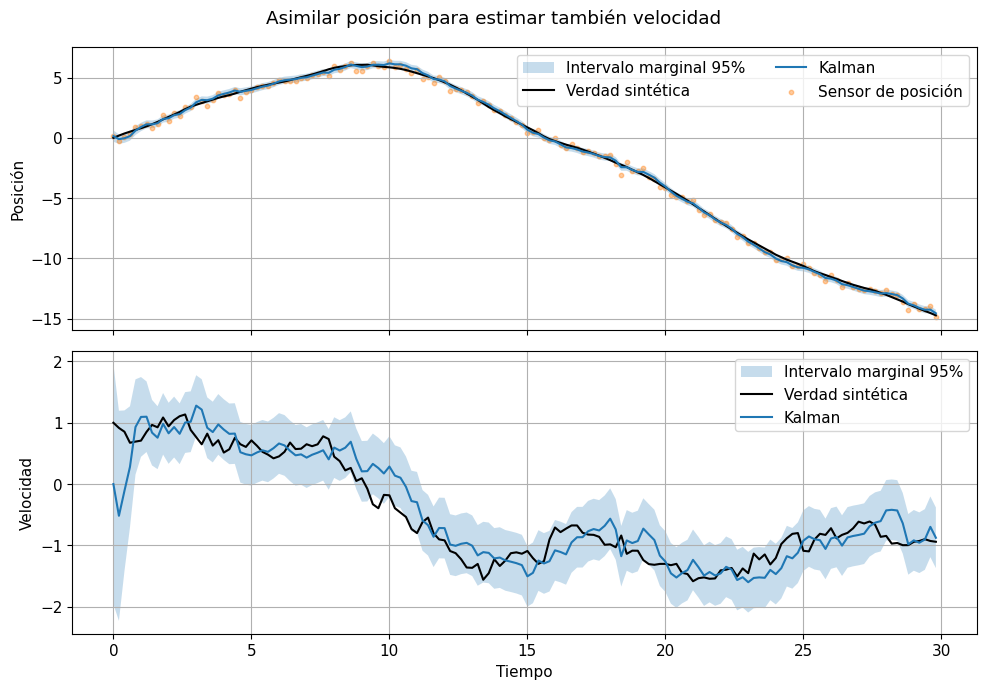

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for j, nombre in enumerate(["Posición", "Velocidad"]):
    sd = np.sqrt(P_kf[:, j, j])
    axes[j].fill_between(tiempo, m_kf[:, j]-1.96*sd, m_kf[:, j]+1.96*sd, alpha=0.25, label="Intervalo marginal 95%")
    axes[j].plot(tiempo, truth[:, j], "k-", label="Verdad sintética")
    axes[j].plot(tiempo, m_kf[:, j], label="Kalman")
    axes[j].set(ylabel=nombre)
axes[0].scatter(tiempo, y, s=10, alpha=0.4, label="Sensor de posición")
axes[0].legend(ncol=2); axes[1].legend(); axes[1].set_xlabel("Tiempo")
fig.suptitle("Asimilar posición para estimar también velocidad")
plt.tight_layout(); plt.show()

## 6. Diagnóstico mediante innovaciones

Bajo el modelo correcto, $z_n=d_n/\sqrt{S_n}$ tiene media cero, varianza uno y ausencia de correlación temporal. Su cuadrado es la innovación normalizada al cuadrado, NIS; para una observación escalar su distribución ideal es $\chi^2_1$.

Un valor alto aislado puede ocurrir por azar. Una media sistemáticamente positiva sugiere sesgo; una autocorrelación marcada sugiere dinámica o ruido mal modelados; una NIS promedio demasiado grande sugiere incertidumbres subestimadas. Los primeros pasos dependen especialmente de la inicialización y se analizarán por separado.

Comparamos el modelo usado para generar datos con otro que reduce artificialmente $Q$ por cien. No esperamos que una trayectoria corta reproduzca exactamente distribuciones teóricas: el diagnóstico aporta evidencia, no una demostración de corrección.

Media y desviación de z: -0.10466897048109636 1.0098165744882082
Correlación a lag 1: 0.010324701875048373


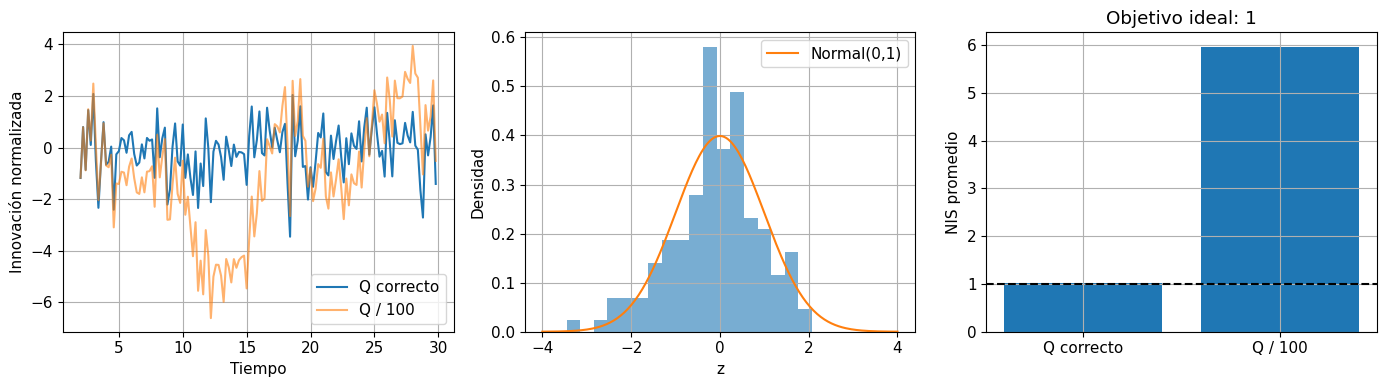

In [4]:
m_rigido, P_rigido, d_rigido, S_rigido, _, _ = kalman(y, q_factor=0.01)
z = innov[10:]/np.sqrt(S_lista[10:])
z_rigido = d_rigido[10:]/np.sqrt(S_rigido[10:])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(tiempo[10:], z, label="Q correcto")
axes[0].plot(tiempo[10:], z_rigido, alpha=0.6, label="Q / 100")
axes[0].set(xlabel="Tiempo", ylabel="Innovación normalizada"); axes[0].legend()
xh = np.linspace(-4, 4, 200)
axes[1].hist(z, bins=18, density=True, alpha=0.6)
axes[1].plot(xh, np.exp(-xh*xh/2)/np.sqrt(2*np.pi), label="Normal(0,1)")
axes[1].set(xlabel="z", ylabel="Densidad"); axes[1].legend()
axes[2].bar(["Q correcto", "Q / 100"], [np.mean(z*z), np.mean(z_rigido*z_rigido)])
axes[2].axhline(1, color="k", ls="--")
axes[2].set(ylabel="NIS promedio", title="Objetivo ideal: 1")
plt.tight_layout(); plt.show()
print("Media y desviación de z:", z.mean(), z.std(ddof=1))
print("Correlación a lag 1:", np.corrcoef(z[:-1], z[1:])[0, 1])

## 7. Datos faltantes y valores atípicos

Si no hay observación, la predicción sigue disponible y su incertidumbre aumenta. En el ejemplo omitiremos un segmento de datos. Además introduciremos una lectura defectuosa para ver cómo se propaga su efecto.

Una compuerta que rechaza $|z|>4$ es una estrategia sencilla de control de calidad, pero no sustituye un modelo robusto: si la dinámica real cambia de manera brusca, podría rechazar información válida. El filtrado selectivo también cambia la distribución de innovaciones aceptadas, por lo que no debemos compararla ingenuamente con la normal original.

Observaciones finitas rechazadas: [95]


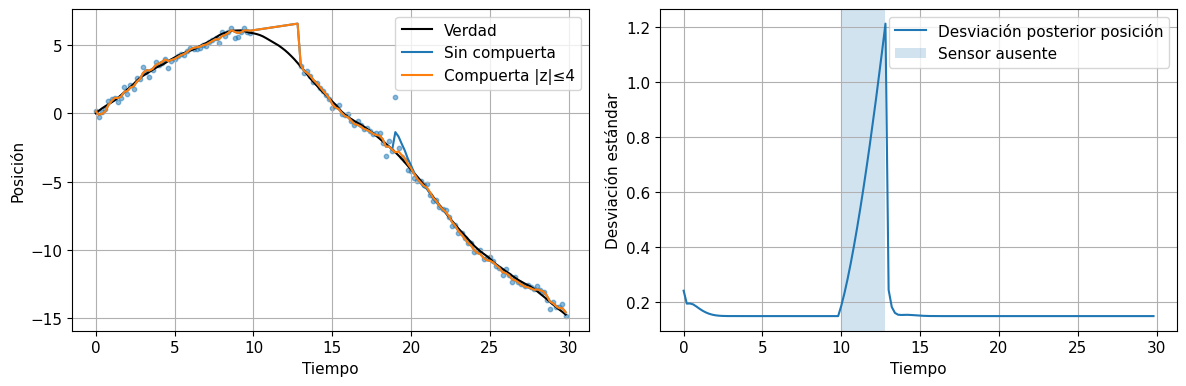

In [5]:
y_defectuoso = y.copy()
y_defectuoso[50:65] = np.nan
y_defectuoso[95] += 4.0
m_sin, P_sin, *_ = kalman(y_defectuoso)
m_gate, P_gate, _, _, _, accept = kalman(y_defectuoso, compuerta=4.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tiempo, truth[:, 0], "k", label="Verdad")
axes[0].plot(tiempo, m_sin[:, 0], label="Sin compuerta")
axes[0].plot(tiempo, m_gate[:, 0], label="Compuerta |z|≤4")
axes[0].scatter(tiempo, y_defectuoso, s=10, alpha=0.5)
axes[0].set(xlabel="Tiempo", ylabel="Posición"); axes[0].legend()
axes[1].plot(tiempo, np.sqrt(P_sin[:, 0, 0]), label="Desviación posterior posición")
axes[1].axvspan(tiempo[50], tiempo[64], alpha=0.2, label="Sensor ausente")
axes[1].set(xlabel="Tiempo", ylabel="Desviación estándar"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Observaciones finitas rechazadas:", np.flatnonzero(np.isfinite(y_defectuoso) & ~accept))

## 8. Filtro de Kalman de conjuntos (EnKF)

En estados grandes, almacenar una matriz $P$ de tamaño $d\times d$ puede ser imposible. El EnKF aproxima distribución y covarianza mediante $M$ miembros. Cada miembro se propaga con el modelo, se calcula la covarianza muestral y se corrige con la ganancia estimada.

Para un filtro con observaciones perturbadas,
$$x_n^{a,(j)}=x_n^{f,(j)}+K_n\left[y_n+\varepsilon_n^{(j)}-Hx_n^{f,(j)}\right].$$
Las perturbaciones son necesarias en esta variante para representar el aporte de $R$ a la covarianza del análisis; existen variantes deterministas de raíz cuadrada que no las usan.

El rango de la covarianza de un conjunto es como máximo $M-1$. En problemas espaciales se suelen utilizar localización e inflación para reducir correlaciones espurias y colapso del conjunto. El ejemplo lineal permite contrastar el resultado con Kalman exacto antes de pasar a un solver no lineal.

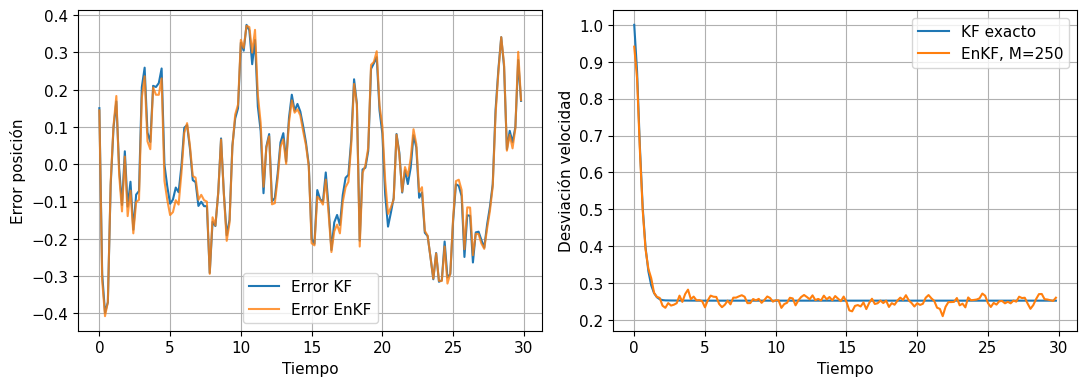

In [6]:
M = 250
rr = np.random.default_rng(172)
ensemble = rr.multivariate_normal([0.0, 0.0], np.eye(2), size=M)
medias_enkf, sd_enkf = [], []
for n, dato in enumerate(y):
    if n > 0:
        ensemble = ensemble @ F.T + rr.multivariate_normal([0.0, 0.0], Q, size=M)
    Pc = np.cov(ensemble, rowvar=False, ddof=1)
    Kc = (Pc @ H.T)/(float((H @ Pc @ H.T).item())+R)
    y_pert = dato + rr.normal(0, np.sqrt(R), M)
    diferencias = y_pert-ensemble[:, 0]
    ensemble = ensemble + diferencias[:, None]*Kc[:, 0][None, :]
    medias_enkf.append(ensemble.mean(axis=0)); sd_enkf.append(ensemble.std(axis=0, ddof=1))
medias_enkf, sd_enkf = np.array(medias_enkf), np.array(sd_enkf)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(tiempo, m_kf[:, 0]-truth[:, 0], label="Error KF")
axes[0].plot(tiempo, medias_enkf[:, 0]-truth[:, 0], alpha=0.8, label="Error EnKF")
axes[0].set(xlabel="Tiempo", ylabel="Error posición"); axes[0].legend()
axes[1].plot(tiempo, np.sqrt(P_kf[:, 1, 1]), label="KF exacto")
axes[1].plot(tiempo, sd_enkf[:, 1], label="EnKF, M=250")
axes[1].set(xlabel="Tiempo", ylabel="Desviación velocidad"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Asimilación variacional: el mismo análisis como mínimo

Para prior $x\sim\mathcal N(m^f,P^f)$ y una observación lineal, maximizar la posterior equivale a minimizar
$$J(x)=\frac12(x-m^f)^T(P^f)^{-1}(x-m^f)+\frac12(y-Hx)^TR^{-1}(y-Hx).$$
El primer término penaliza apartarse del pronóstico según su incertidumbre; el segundo penaliza incompatibilidad con el sensor. Derivar y anular el gradiente reproduce la actualización de Kalman. Es un ejemplo de 3D-Var con covarianza de fondo conocida.

En 4D-Var se optimiza un estado inicial usando observaciones de toda una ventana y la propagación del modelo entre ellas. Un adjunto o autodiferenciación permite obtener gradientes de esa ventana. Si la dinámica es caótica o la ventana muy larga, el problema puede ser difícil y no convexo.

Análisis variacional: [2.35555556 0.88533333] Análisis Kalman: [2.35555556 0.88533333]


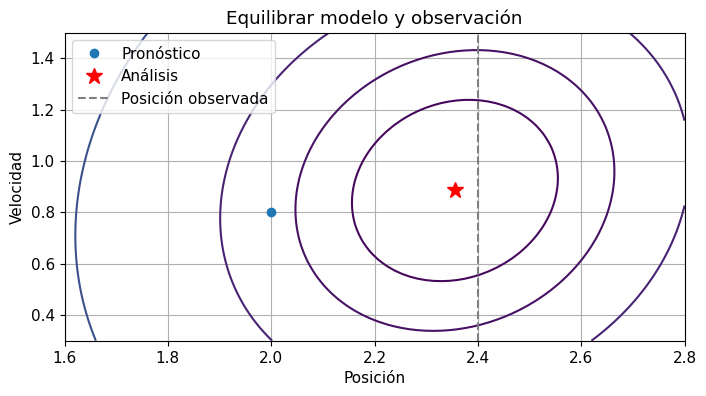

In [7]:
mf = np.array([2.0, 0.8])
Pf = np.array([[0.5, 0.12], [0.12, 0.2]])
y_uno = 2.4

def coste(x):
    delta = x-mf
    residual = y_uno-(H @ x).item()
    return 0.5*delta @ np.linalg.solve(Pf, delta)+0.5*residual**2/R

def gradiente(x):
    return np.linalg.solve(Pf, x-mf)-H[0]*(y_uno-(H @ x).item())/R

opt = minimize(coste, mf, jac=gradiente, method="BFGS", options={"gtol": 1e-9})
K_uno = (Pf @ H.T)/((H @ Pf @ H.T).item()+R)
ma = mf+K_uno[:, 0]*(y_uno-(H @ mf).item())
print("Análisis variacional:", opt.x, "Análisis Kalman:", ma)
assert np.allclose(opt.x, ma, atol=1e-7)
pp, vv = np.meshgrid(np.linspace(1.6, 2.8, 80), np.linspace(0.3, 1.5, 80))
JJ = np.array([coste(z) for z in np.column_stack([pp.ravel(), vv.ravel()])]).reshape(pp.shape)
fig, ax = plt.subplots()
ax.contour(pp, vv, JJ, levels=[0.1, 0.5, 1, 2, 5, 10, 20])
ax.plot(*mf, "o", label="Pronóstico"); ax.plot(*ma, "r*", ms=12, label="Análisis")
ax.axvline(y_uno, ls="--", color="gray", label="Posición observada")
ax.set(xlabel="Posición", ylabel="Velocidad", title="Equilibrar modelo y observación")
ax.legend(); plt.show()

## 10. Observabilidad y qué no puede inferirse

Medir posición dos veces bajo este modelo informa sobre velocidad. La matriz de observabilidad de dos pasos es
$$\mathcal O=\begin{pmatrix}H\\HF\end{pmatrix}=\begin{pmatrix}1&0\\1&\Delta t\end{pmatrix},$$
con determinante $\Delta t$. Si $\Delta t\ne0$ tiene rango dos. Esto no garantiza estimaciones precisas: con tiempos casi iguales o ruido grande la inferencia de velocidad puede ser muy sensible.

Identificar simultáneamente estado y parámetros es aún más delicado. Añadir $k$ al estado de una ecuación de enfriamiento no crea automáticamente información sobre $k$; hacen falta observaciones que distingan su efecto de la amplitud o del sesgo del sensor.

## 11. Filtrado, suavizado y aprendizaje

**Filtrar** estima $x_n$ usando datos hasta $n$; **suavizar** usa también observaciones futuras. El suavizado puede reconstruir mejor trayectorias históricas, pero no es una predicción disponible en tiempo real. **Aprender parámetros** estima la ley dinámica, mientras asimilar estima estados de una ley dada; se pueden combinar, siempre evitando usar datos futuros accidentalmente al evaluar pronósticos.

En SciML, un neural operator puede sustituir parte de la propagación, y un modelo híbrido puede aprender una corrección al solver. Deben conservarse diagnósticos de incertidumbre e innovaciones. Un emulador rápido con sesgo sistemático puede hacer que el filtro parezca seguro mientras se aleja de la trayectoria real.

## 12. Comparaciones científicas honestas

Para comparar métodos, usa la misma verdad y los mismos sensores, separa periodos de ajuste y evaluación, e informa tanto RMSE como cobertura, costo y sensibilidad a $Q$ y $R$. Los conjuntos deben tener semillas repetidas: una sola realización del EnKF puede parecer mejor o peor por azar.

Este cuaderno usa un problema lineal gaussiano en el que Kalman es una referencia exacta para la distribución condicional. El EnKF no mejora esa solución exacta; demuestra una aproximación que puede resultar viable cuando el estado es enorme o el modelo es no lineal.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../16_UNCERTAINTY_QUANTIFICATION/16_1_UNCERTAINTY_QUANTIFICATION.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_1_Performance.ipynb) |